# Heuristic/metaheuristic method: Simulated Annealing

Clarke–Wright is used **only to initialize feasible routes**; the reported heuristic is SA.


In [1]:
%pip -q install ortools numpy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 6.5 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import math, time, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("/content/cvrp_data") if Path("/content").exists() else Path("cvrp_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = Path("/content/cvrp_outputs") if Path("/content").exists() else Path("cvrp_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# In Colab, upload the three actual .vrp files when prompted.
files_found = sorted(DATA_DIR.glob("*.vrp"))
if not files_found:
    try:
        from google.colab import files
        print("Upload your THREE CVRPLIB .vrp files (not screenshots).")
        uploaded = files.upload()
        for filename, data in uploaded.items():
            if filename.lower().endswith(".vrp"):
                (DATA_DIR / Path(filename).name).write_bytes(data)
    except ImportError:
        print(f"Local execution: copy the .vrp files into {DATA_DIR.resolve()}")
files_found = sorted(DATA_DIR.glob("*.vrp"))
if len(files_found) != 3:
    raise FileNotFoundError(f"Expected exactly 3 .vrp files in {DATA_DIR}; found {len(files_found)}: {[p.name for p in files_found]}")
print("Using actual files:", [p.name for p in files_found])

Upload your THREE CVRPLIB .vrp files (not screenshots).


Saving A-n32-k5.vrp to A-n32-k5.vrp
Saving A-n34-k5.vrp to A-n34-k5.vrp
Saving A-n37-k5.vrp to A-n37-k5.vrp
Using actual files: ['A-n32-k5.vrp', 'A-n34-k5.vrp', 'A-n37-k5.vrp']


In [3]:
def load_vrp(path):
    """Read standard CVRPLIB TSPLIB CVRP with NODE_COORD_SECTION, DEMAND_SECTION, DEPOT_SECTION."""
    text = Path(path).read_text(encoding="utf-8-sig")
    header, sections = {}, {}
    section = None
    for raw in text.splitlines():
        line = raw.strip()
        if not line or line == "EOF": continue
        if line.endswith("_SECTION"):
            section = line
            sections[section] = []
        elif section:
            sections[section].append(line)
        else:
            if ":" in line:
                k, v = line.split(":", 1)
            else:
                tokens = line.split(None, 1)
                if len(tokens) != 2: continue
                k, v = tokens
            header[k.strip().upper()] = v.strip()
    if header.get("TYPE", "CVRP").upper() != "CVRP":
        raise ValueError(f"{path}: expected TYPE CVRP")
    if header.get("EDGE_WEIGHT_TYPE", "EUC_2D").upper() != "EUC_2D":
        raise ValueError(f"{path}: this notebook requires EUC_2D coordinates")
    coords_by_id = {}
    for row in sections.get("NODE_COORD_SECTION", []):
        vals = row.split()
        coords_by_id[int(vals[0])] = (float(vals[1]), float(vals[2]))
    demands_by_id = {}
    for row in sections.get("DEMAND_SECTION", []):
        vals = row.split()
        demands_by_id[int(vals[0])] = int(vals[1])
    depot_ids = [int(v.split()[0]) for v in sections.get("DEPOT_SECTION", [])
                 if int(v.split()[0]) != -1]
    if len(depot_ids) != 1:
        raise ValueError(f"{path}: expected exactly one depot, got {depot_ids}")
    depot = depot_ids[0]
    if set(coords_by_id) != set(demands_by_id):
        raise ValueError(f"{path}: coordinate and demand IDs differ")
    ids = [depot] + sorted(i for i in coords_by_id if i != depot)
    n = len(ids)
    if int(header.get("DIMENSION", n)) != n:
        raise ValueError(f"{path}: DIMENSION mismatch")
    coords = np.array([coords_by_id[i] for i in ids], dtype=float)
    demands = np.array([demands_by_id[i] for i in ids], dtype=int)
    if demands[0] != 0: raise ValueError("Depot demand must be zero")
    capacity = int(header["CAPACITY"])
    # CVRPLIB EUC_2D convention: nearest integer (nonnegative distances).
    dist = np.floor(np.linalg.norm(coords[:,None,:]-coords[None,:,:], axis=2)+0.5).astype(int)
    import re
    m = re.search(r"-k(\d+)", path.stem, re.I)
    if not m:
        raise ValueError(f"{path.name}: cannot infer fleet size from -kN filename; set it explicitly")
    vehicles = int(m.group(1))
    if np.any(demands[1:] > capacity): raise ValueError("Customer demand exceeds capacity")
    if demands.sum() > vehicles * capacity: raise ValueError("Fleet capacity is insufficient")
    return dict(name=path.stem, path=str(path), coords=coords, demands=demands,
                dist=dist, n=n, K=vehicles, capacity=capacity, ids=ids)

INSTANCES = [load_vrp(p) for p in files_found]
# Published best-known optima for these listed benchmark instances only.
KNOWN_OPTIMA = {"A-n32-k5":784, "A-n33-k5":661, "A-n34-k5":778,
                "A-n36-k5":799, "A-n37-k5":669}
info = pd.DataFrame([{"instance":i["name"], "customers":i["n"]-1,
                      "vehicles":i["K"], "capacity":i["capacity"],
                      "total_demand":int(i["demands"].sum()),
                      "published_optimum":KNOWN_OPTIMA.get(i["name"])}
                     for i in INSTANCES])
display(info)
info.to_csv(OUTPUT_DIR/"instance_summary.csv",index=False)

def route_cost(instance, route):
    d = instance["dist"]
    seq = [0] + list(route) + [0]
    return int(sum(d[a,b] for a,b in zip(seq, seq[1:])))

def solution_cost(instance, routes):
    return sum(route_cost(instance,r) for r in routes)

def validate(instance, routes):
    customers = [v for r in routes for v in r]
    expected = set(range(1,instance["n"]))
    counts = {v:customers.count(v) for v in customers}
    duplicate = sorted(v for v,c in counts.items() if c > 1)
    missing = sorted(expected-set(customers))
    unexpected = sorted(set(customers)-expected)
    loads = [int(sum(instance["demands"][v] for v in r if v in expected)) for r in routes]
    feasible = (not missing and not duplicate and not unexpected
                and len(routes) <= instance["K"]
                and all(0 < load <= instance["capacity"] for load in loads))
    return {"feasible":bool(feasible), "routes":len(routes), "loads":loads,
            "missing":missing,"duplicate":duplicate,"unexpected":unexpected}

def plot_routes(instance, routes, title, filename=None):
    xy = instance["coords"]
    fig, ax = plt.subplots(figsize=(7,6))
    ax.scatter(xy[1:,0],xy[1:,1],s=22,label="Customers",zorder=3)
    ax.scatter(xy[0,0],xy[0,1],marker="*",s=220,label="Depot",zorder=4)
    for j,r in enumerate(routes):
        seq = [0]+list(r)+[0]
        ax.plot(xy[seq,0],xy[seq,1],label=f"Vehicle {j+1}")
    ax.set(title=title,xlabel="X coordinate",ylabel="Y coordinate")
    ax.legend(fontsize=7,loc="best")
    fig.tight_layout()
    if filename: fig.savefig(OUTPUT_DIR/filename,dpi=160,bbox_inches="tight")
    plt.show()

,instance,customers,vehicles,capacity,total_demand,published_optimum
0,A-n32-k5,31,5,100,410,784
1,A-n34-k5,33,5,100,460,778
2,A-n37-k5,36,5,100,407,669


In [4]:
def clarke_wright(instance):
    n, d, demands = instance["n"],instance["dist"],instance["demands"]
    Q, K = instance["capacity"],instance["K"]
    routes = {i:[i] for i in range(1,n)}
    membership = {i:i for i in range(1,n)}
    savings = sorted(((int(d[0,i]+d[0,j]-d[i,j]),i,j)
                      for i in range(1,n) for j in range(i+1,n)),reverse=True)
    for _,i,j in savings:
        ri,rj = membership[i],membership[j]
        if ri == rj: continue
        a,b = routes[ri],routes[rj]
        if i not in (a[0],a[-1]) or j not in (b[0],b[-1]): continue
        if sum(demands[v] for v in a+b)>Q: continue
        aa = a if a[-1]==i else a[::-1]
        bb = b if b[0]==j else b[::-1]
        merged = aa+bb
        routes[ri] = merged
        del routes[rj]
        for v in merged: membership[v] = ri
    # Standard savings may leave more routes than the allowed fleet.
    # Merge feasible pairs with smallest added distance until <= K.
    while len(routes)>K:
        choices = []
        keys = list(routes)
        for idx,ki in enumerate(keys):
            for kj in keys[idx+1:]:
                a,b = routes[ki],routes[kj]
                if sum(demands[v] for v in a+b)>Q: continue
                for aa in (a,a[::-1]):
                    for bb in (b,b[::-1]):
                        delta = route_cost(instance,aa+bb)-route_cost(instance,a)-route_cost(instance,b)
                        choices.append((delta,ki,kj,aa+bb))
        if not choices:
            raise RuntimeError("Clarke-Wright could not reach fleet limit; try a stronger construction")
        _,ki,kj,merged = min(choices,key=lambda t:t[0])
        routes[ki] = merged
        del routes[kj]
    result = list(routes.values())
    check = validate(instance,result)
    if not check["feasible"]: raise RuntimeError(f"Clarke-Wright invalid: {check}")
    return result

def neighbor(instance, routes, rng):
    r = [list(v) for v in routes]
    Q, demands = instance["capacity"],instance["demands"]
    for attempt in range(40):
        cand = [v[:] for v in r]
        move = rng.choice(["swap","relocate","two_opt"])
        if move == "two_opt":
            choices = [i for i,v in enumerate(cand) if len(v)>=2]
            if not choices: continue
            a = rng.choice(choices)
            i,j = sorted(rng.sample(range(len(cand[a])),2))
            cand[a][i:j+1] = cand[a][i:j+1][::-1]
        elif move == "swap":
            a,b = rng.randrange(len(cand)),rng.randrange(len(cand))
            if not cand[a] or not cand[b]: continue
            i,j = rng.randrange(len(cand[a])),rng.randrange(len(cand[b]))
            cand[a][i],cand[b][j] = cand[b][j],cand[a][i]
        else:
            if len(cand)==1: continue
            a,b = rng.sample(range(len(cand)),2)
            if not cand[a]: continue
            i = rng.randrange(len(cand[a]))
            customer = cand[a].pop(i)
            cand[b].insert(rng.randrange(len(cand[b])+1),customer)
            cand = [v for v in cand if v]
        if all(sum(demands[v] for v in route)<=Q for route in cand):
            return cand
    return r

def simulated_annealing(instance, initial, seed=42, iterations=15000,
                        start_temp=100.0, end_temp=0.05):
    rng = random.Random(seed)
    current = [r[:] for r in initial]
    current_cost = solution_cost(instance,current)
    best = [r[:] for r in current]
    best_cost = current_cost
    history = []
    for step in range(iterations):
        temp = start_temp*(end_temp/start_temp)**(step/max(1,iterations-1))
        candidate = neighbor(instance,current,rng)
        cost = solution_cost(instance,candidate)
        delta = cost-current_cost
        if delta<=0 or rng.random()<math.exp(-delta/temp):
            current,current_cost=candidate,cost
        if current_cost<best_cost:
            best,best_cost=[r[:] for r in current],current_cost
        if step%max(1,iterations//200)==0 or step==iterations-1:
            history.append((step+1,best_cost,current_cost))
    check = validate(instance,best)
    if not check["feasible"]: raise RuntimeError(f"SA invalid: {check}")
    return best,pd.DataFrame(history,columns=["iteration","best_cost","current_cost"])

## SA runs on all three instances
The initialization time is included in SA total runtime. Five seeds and 15,000 iterations reproduce the prior experiment settings.

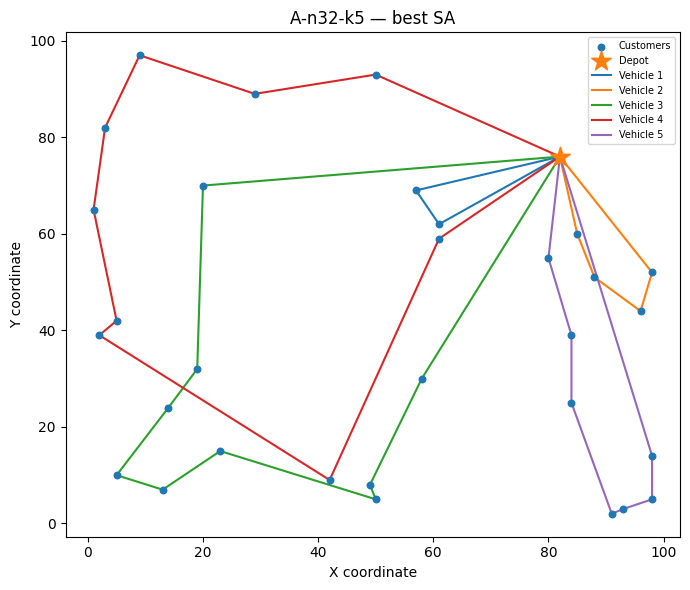

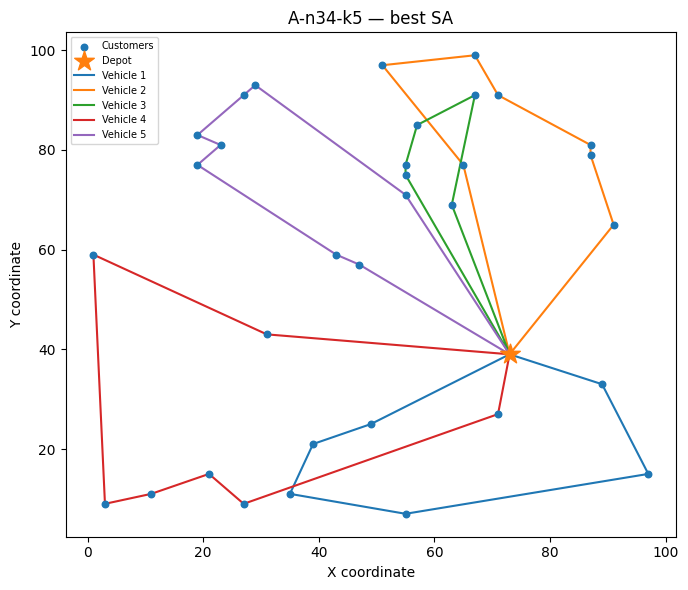

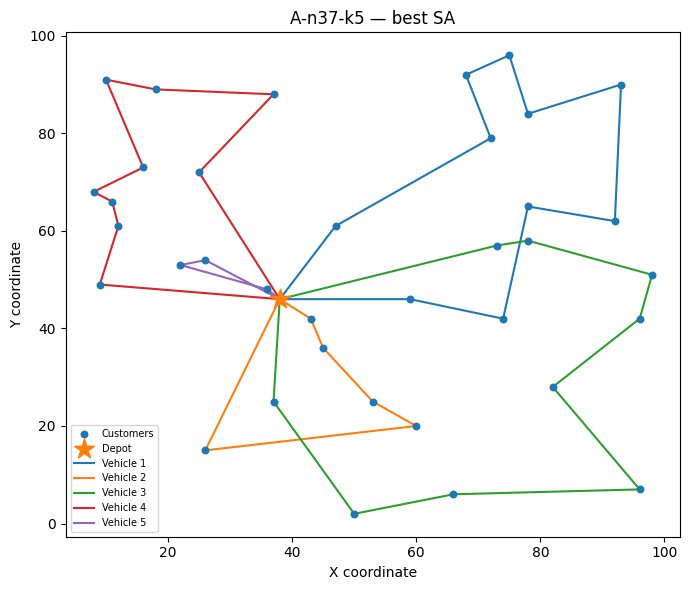

,instance,best_objective,mean_objective,std_objective,mean_runtime_s,feasible_runs,published_optimum,best_gap_pct
0,A-n32-k5,812,831.8,11.734564,0.523046,5,784,3.571429
1,A-n34-k5,796,797.6,0.894427,0.848643,5,778,2.313625
2,A-n37-k5,702,704.4,1.341641,0.564242,5,669,4.932735


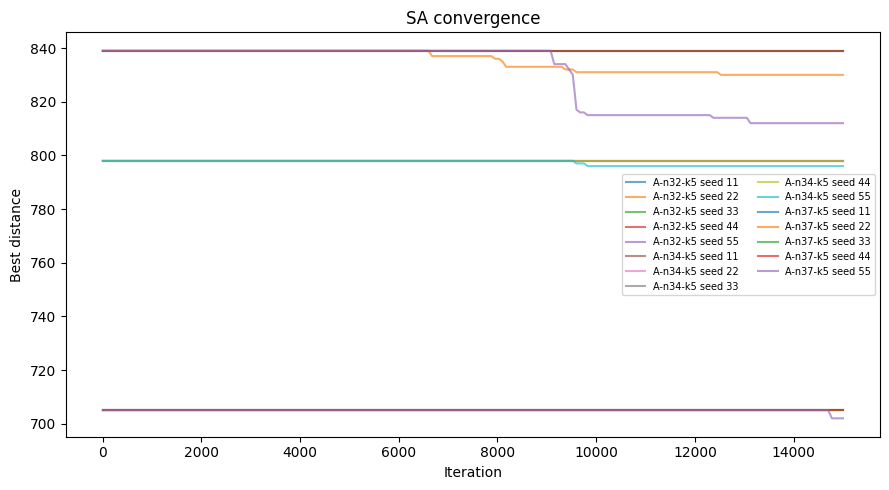

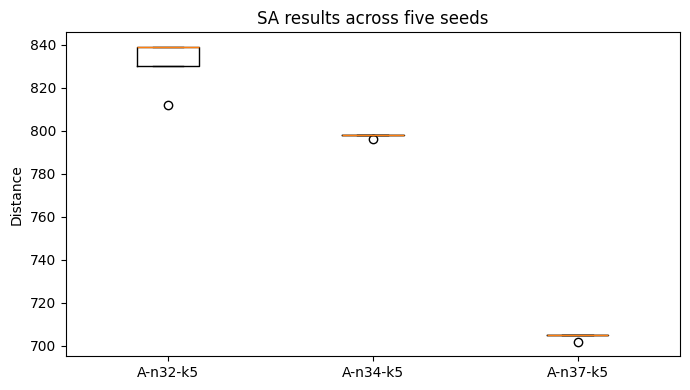

In [5]:
SA_SEEDS=[11,22,33,44,55]
SA_ITERATIONS=15000
rows=[]; traces={}
for inst in INSTANCES:
    start=time.perf_counter()
    initial=clarke_wright(inst)
    init_seconds=time.perf_counter()-start
    best_obj=float('inf'); best_routes=None
    for seed in SA_SEEDS:
        start=time.perf_counter()
        routes,trace=simulated_annealing(inst,initial,seed=seed,iterations=SA_ITERATIONS)
        sa_seconds=time.perf_counter()-start
        objective=solution_cost(inst,routes)
        rows.append(dict(instance=inst['name'],method='Simulated Annealing',seed=seed,objective=objective,
                         runtime_s=init_seconds+sa_seconds,initialization_s=init_seconds,
                         feasible=validate(inst,routes)['feasible'],
                         published_optimum=KNOWN_OPTIMA.get(inst['name'])))
        traces[(inst['name'],seed)]=trace
        trace.to_csv(OUTPUT_DIR/f"{inst['name']}_sa_seed{seed}_convergence.csv",index=False)
        if objective<best_obj:best_obj,best_routes=objective,routes
    plot_routes(inst,best_routes,f"{inst['name']} — best SA",f"{inst['name']}_sa_routes.png")
sa_df=pd.DataFrame(rows)
sa_df['benchmark_gap_pct']=100*(sa_df.objective-sa_df.published_optimum)/sa_df.published_optimum
sa_df.to_csv(OUTPUT_DIR/'sa_all_runs.csv',index=False)
summary=sa_df.groupby('instance').agg(best_objective=('objective','min'),mean_objective=('objective','mean'),std_objective=('objective','std'),mean_runtime_s=('runtime_s','mean'),feasible_runs=('feasible','sum')).reset_index()
summary['published_optimum']=summary.instance.map(KNOWN_OPTIMA)
summary['best_gap_pct']=100*(summary.best_objective-summary.published_optimum)/summary.published_optimum
display(summary);summary.to_csv(OUTPUT_DIR/'sa_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
for (name,seed),trace in traces.items():ax.plot(trace.iteration,trace.best_cost,label=f'{name} seed {seed}',alpha=.65)
ax.set(xlabel='Iteration',ylabel='Best distance',title='SA convergence');ax.legend(fontsize=7,ncol=2);fig.tight_layout();fig.savefig(OUTPUT_DIR/'sa_convergence.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4));ax.boxplot([sa_df[sa_df.instance==inst['name']].objective for inst in INSTANCES],tick_labels=[inst['name'] for inst in INSTANCES]);ax.set(ylabel='Distance',title='SA results across five seeds');fig.tight_layout();fig.savefig(OUTPUT_DIR/'sa_variability.png',dpi=160);plt.show()
